# 08 · Holdout-валидация: две метрики и bootstrap

Шаг 9 плана. Всегда две оси: ранжирование (Gini, Lorenz, decile capture) и
калибровка (MAE/RMSE, calibration ratio по срезам). Bootstrap по клиентам — 1 000
ресурсов, один `Generator`; сравнение без интервала не публикуется.

In [1]:
import sys
sys.path.insert(0, '../..'); sys.path.insert(0, '../src')
import json
from inspect import signature
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from paths import CASE_LTV, PROCESSED, RANDOM_SEED, figures
from features import (CUTOFF_DATE, HORIZON_MONTHS, B3_T_DAYS, B3_FIT_MONTHS,
                      DAYS_IN_AGE_MONTH, split_transactions, calibration_features,
                      calibration_revenue, build_target, lifecycle_transactions,
                      first_purchase_dates, pre_first_mask, customer_country,
                      cohort_tables, pooled_curve, extend_survival,
                      extend_cumulative_revenue, age_months)
from metrics import (gini, top_capture, top_lift, decile_capture, lorenz_points,
                     mae, rmse, calibration_ratio, model_metrics, bootstrap_ci,
                     bootstrap_diff, calibration_by, coverage_at_top,
                     smallest_segment_for_coverage, shrink_predictions)
from models import (fit_bgnbd, fit_mbg_nbd, fit_pareto_nbd, fit_gamma_gamma,
                    bgnbd_loglik, bgnbd_expected_purchases, mbg_nbd_loglik,
                    mbg_nbd_expected_purchases, pareto_nbd_loglik,
                    pareto_nbd_expected_purchases, gamma_gamma_loglik,
                    gamma_gamma_mean, gamma_gamma_conditional_spend,
                    monthly_expected_purchases, discounted_revenue, aic)
from plots import (plot_split_timeline, plot_lorenz, plot_model_comparison,
                   plot_calibration_by_decile, plot_horizon, plot_segments,
                   plot_shrinkage, plot_posterior)
FIG = figures(CASE_LTV); FIG.mkdir(parents=True, exist_ok=True)
RNG = np.random.default_rng(RANDOM_SEED)
tx = pd.read_parquet(PROCESSED / 'transactions.parquet')

split = pd.read_parquet(PROCESSED / 'ltv_split.parquet')
base = pd.read_parquet(PROCESSED / 'baselines.parquet')
purch = pd.read_parquet(PROCESSED / 'purchases.parquet')
spend = pd.read_parquet(PROCESSED / 'spend.parquet')
d = split.join(base[['B1', 'B2', 'B3', 'B4']]).join(purch).join(spend[['spend_main']])
y = d.revenue_holdout.to_numpy(float)
d['BG'] = d.BG_bayes * d.spend_main
d['MBG'] = d.MBG * d.spend_main
d['Pareto'] = d.Pareto * d.spend_main
d['BG_no_one_time'] = d.BG_no_one_time * d.spend_main
models = ['B1', 'B2', 'B3', 'B4', 'BG', 'MBG', 'Pareto', 'BG_no_one_time']
assert d[models].notna().all().all()


## §5а-4: произведение уже проинтегрировано по «жив/мёртв»

In [2]:
def clv_from_purchases(purchases, spend):
    """CLV = E[покупки] × E[чек]. E[покупки] уже интегрировано по alive/dead;
    p(alive) сюда не входит и повторно не умножается."""
    return purchases * spend

assert 'p_alive' not in clv_from_purchases.__code__.co_varnames
d['BG_check'] = clv_from_purchases(d.BG_bayes.to_numpy(), d.spend_main.to_numpy())
assert np.allclose(d.BG_check, d.BG)


## §5а-3 на выходе CLV

In [3]:
assert not np.isclose((d.BG == 0).mean(), (d.frequency == 0).mean(), atol=0.02)
print('доля нулей в CLV:', f'{(d.BG == 0).mean():.1%}', '· доля frequency=0:', f'{(d.frequency == 0).mean():.1%}')


доля нулей в CLV: 0.0% · доля frequency=0: 35.2%


## Таблица «модель × метрика»

In [4]:
rows = []
for m in models:
    rows.append({'model': m, **model_metrics(y, d[m].to_numpy(float))})
table = pd.DataFrame(rows).set_index('model')
table.round(4)


,gini,top10_capture,top10_lift,top20_capture,mae,rmse,calibration_ratio
model,,,,,,,
B1,0.7036,0.6096,6.0961,0.7388,1080.5227,4066.2918,1.2419
B2,0.3478,0.2762,2.7619,0.4399,2112.9004,7960.4240,1.2419
B3,0.5932,0.5065,5.0653,0.6416,2128.2723,9366.1558,1.7295
B4,0.6282,0.5246,5.2464,0.6651,1465.9200,6294.1502,0.8647
BG,0.6971,0.6108,6.1075,0.7439,1254.9926,4001.7332,1.3639
MBG,0.6970,0.6032,6.0325,0.7429,1258.5970,4019.6191,1.3573
Pareto,0.6969,0.6034,6.0338,0.7429,1266.9312,4028.2715,1.3556
BG_no_one_time,0.6864,0.6046,6.0456,0.7327,1483.6003,4106.3209,1.5269


## Bootstrap-CI на Gini и top-10 % capture

In [5]:
ci_rows = []
for m in models:
    for metric_name, fn in [('gini', gini), ('top10_capture', lambda a, b: top_capture(a, b, .10))]:
        r = bootstrap_ci(y, d[m].to_numpy(float), fn, RNG, n_boot=1000)
        ci_rows.append({'model': m, 'metric': metric_name,
                        'point': r['point'], 'lo': r['lo'], 'hi': r['hi'], 'n_boot': 1000})
ci = pd.DataFrame(ci_rows)
ci.pivot(index='model', columns='metric', values=['point', 'lo', 'hi']).round(4)


point                    lo                    hi  \
metric            gini top10_capture    gini top10_capture    gini   
model                                                                
B1              0.7036        0.6096  0.6575        0.5484  0.7449   
B2              0.3478        0.2762  0.2602        0.1656  0.4182   
B3              0.5932        0.5065  0.5291        0.4222  0.6500   
B4              0.6282        0.5246  0.5696        0.4513  0.6812   
BG              0.6971        0.6108  0.6499        0.5474  0.7404   
BG_no_one_time  0.6864        0.6046  0.6363        0.5381  0.7296   
MBG             0.6970        0.6032  0.6488        0.5472  0.7371   
Pareto          0.6969        0.6034  0.6475        0.5382  0.7388   

                              
metric         top10_capture  
model                         
B1                    0.6630  
B2                    0.3108  
B3                    0.5824  
B4                    0.5994  
BG                    0.6630  
BG_no_one_time        0.6600  
MBG                   0.6590  
Pareto                0.6634

## Парные сравнения: BG/NBD против бейзлайнов

In [6]:
cmp_rows = []
for other in ['B1', 'B3', 'B4', 'MBG', 'Pareto']:
    r = bootstrap_diff(y, d.BG.to_numpy(float), d[other].to_numpy(float), gini, RNG, n_boot=1000)
    cmp_rows.append({'comparison': f'BG − {other}', 'metric': 'gini', **r})
    r2 = bootstrap_diff(y, d.BG.to_numpy(float), d[other].to_numpy(float),
                        lambda a, b: top_capture(a, b, .10), RNG, n_boot=1000)
    cmp_rows.append({'comparison': f'BG − {other}', 'metric': 'top10_capture', **r2})
compare = pd.DataFrame(cmp_rows)
compare.round(4)


,comparison,metric,point,lo,hi
0,BG − B1,gini,-0.0065,-0.0143,0.0003
1,BG − B1,top10_capture,0.0011,-0.0206,0.0108
2,BG − B3,gini,0.1039,0.0834,0.1287
3,BG − B3,top10_capture,0.1042,0.0750,0.1314
4,BG − B4,gini,0.0688,0.0531,0.0871
5,BG − B4,top10_capture,0.0861,0.0598,0.1050
6,BG − MBG,gini,0.0001,-0.0004,0.0006
7,BG − MBG,top10_capture,0.0075,-0.0038,0.0174
8,BG − Pareto,gini,0.0002,-0.0005,0.0008
9,BG − Pareto,top10_capture,0.0074,-0.0057,0.0183


Интерпретация: интервал разницы не пересекает 0 — преимущество есть; пересекает —
разница неотличима от шума. Это и есть правило §6 conventions: метрика, окно,
бейзлайн, интервал.

## Калибровка по срезам: когорта, страна, бэнд прогноза

In [7]:
cal_cohort = calibration_by(y, d.BG.to_numpy(), d.cohort.to_numpy())
top_countries = d.country.value_counts().head(6).index
country_group = np.where(d.country.isin(top_countries), d.country, 'other')
cal_country = calibration_by(y, d.BG.to_numpy(), country_group)
band = pd.qcut(d.BG.rank(method='first'), 10, labels=False) + 1
cal_band = calibration_by(y, d.BG.to_numpy(), band.to_numpy())
print('flag по когортам:', int(cal_cohort.flag.sum()), 'из', len(cal_cohort))
print('flag по странам:', int(cal_country.flag.sum()), 'из', len(cal_country))
print('flag по децилям:', int(cal_band.flag.sum()), 'из', len(cal_band))
cal_band.round(3)


flag по когортам: 10 из 12
flag по странам: 4 из 7
flag по децилям: 9 из 10


,group,n,actual,pred,ratio,flag
0,1,424,99.882,271.975,2.723,True
1,2,424,252.211,449.464,1.782,True
2,3,424,282.170,649.856,2.303,True
3,4,424,378.041,838.926,2.219,True
4,5,424,396.979,1041.611,2.624,True
5,7,424,760.487,1543.047,2.029,True
6,9,424,2049.428,2847.417,1.389,True
7,8,424,1152.077,1994.064,1.731,True
8,10,424,9399.402,10100.152,1.075,False
9,6,423,620.609,1257.347,2.026,True


Calibration ratio = mean(pred)/mean(actual); флаг вне [0.8, 1.2]. Для BG/NBD
уровень систематически выше факта (ratio ≈ 1.35): это ограничение модели на этом
окне, а не ошибка ранжирования.

In [8]:
cal_cohort.to_csv(PROCESSED / 'calibration_by_cohort.csv', index=False)
cal_country.to_csv(PROCESSED / 'calibration_by_country.csv', index=False)
cal_band.to_csv(PROCESSED / 'calibration_by_band.csv', index=False)


## Графики

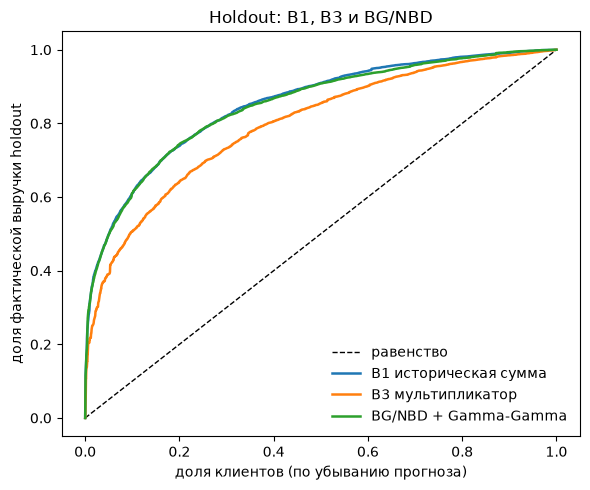

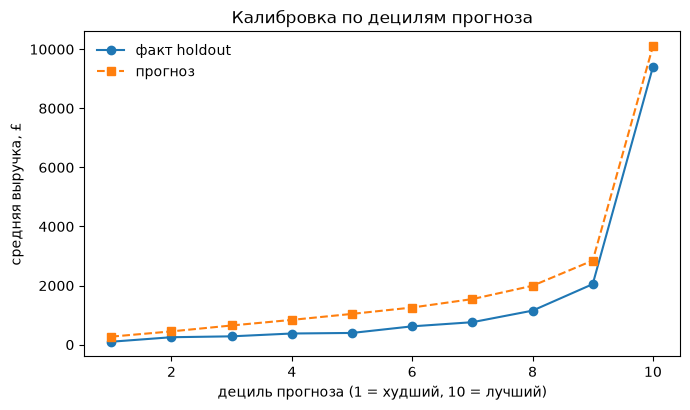

In [9]:
plot_lorenz(y, {'B1 историческая сумма': d.B1, 'B3 мультипликатор': d.B3,
                 'BG/NBD + Gamma-Gamma': d.BG},
           FIG / '12-lorenz-holdout.png', title='Holdout: B1, B3 и BG/NBD')
plt.show()
plot_calibration_by_decile(y, d.BG.to_numpy(), FIG / '13-calibration-deciles.png')
plt.show()


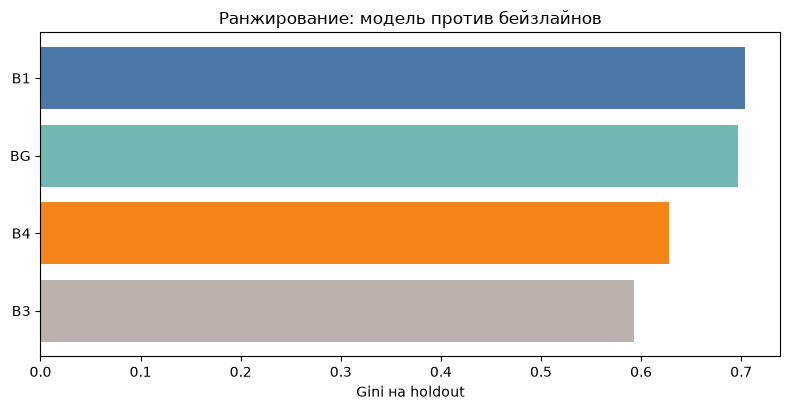

In [10]:
fig, ax = plt.subplots(figsize=(8, 4.2))
t = table.loc[['B1', 'B3', 'B4', 'BG']].sort_values('gini')
ax.barh(t.index, t.gini, color=['#BAB0AC', '#F58518', '#72B7B2', '#4C78A8'])
ax.set(xlabel='Gini на holdout', title='Ранжирование: модель против бейзлайнов')
fig.tight_layout(); fig.savefig(FIG / '14-model-comparison.png'); plt.show()


In [11]:
d[models + ['spend_main']].to_parquet(PROCESSED / 'validation.parquet')
table.to_csv(PROCESSED / 'model_metrics.csv')
ci.to_csv(PROCESSED / 'bootstrap_ci.csv', index=False)
compare.to_csv(PROCESSED / 'model_comparison.csv', index=False)


Главный результат: BG/NBD обыгрывает B3 и B4 с интервалом, но B1 остаётся
чуть впереди. Это не провал, а граница применимости: историческая сумма сильна на
12/12-сплите, где размер клиента уже виден; модель добавляет p(alive) и работает
там, где истории мало.